# 04 · full CRAG + simple RAG vs CRAG

Notebook 5 of 5. Reference: Yan et al., 2024, [Corrective Retrieval Augmented Generation](https://arxiv.org/abs/2401.15884).

## what this one is

01 to 03 built CRAG one piece at a time, with lots of testing and printing in between. Here I just want:

1. the whole pipeline in one place, cleaned up, no experiments in the middle
2. a proper comparison of simple RAG vs CRAG on all the test questions. not just "the answers look better" but
   actually checking if each answer is supported by what it was given, plus what it costs

## how I got here (short version)

- 00: plain RAG trusts retrieval blindly. strict prompt gives "I don't know", loose prompt leaks from memory, and the
  half covered SVM vs XGBoost question leaked even with the strict prompt
- 01: retrieval evaluator + verdicts + knowledge refinement. had to rewrite the evaluator prompt because v1 gave half
  relevant chunks 0
- 02: INCORRECT goes to the web. query rewrite, Tavily (with the date filter for recent stuff), refine the web results
- 03: AMBIGUOUS uses book + web together. three branches became two

---
# the pipeline

## config

In [1]:
import os
import re
import time
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)  # langchain-community sunset notice
from pathlib import Path
from typing import Literal, TypedDict
from urllib.parse import urlparse

import pandas as pd
from dotenv import load_dotenv
from langchain_community.callbacks import get_openai_callback
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from tavily import TavilyClient

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

INDEX_DIR = PROJECT_ROOT / "vectorstore" / "faiss_index"
assert INDEX_DIR.exists(), "Run 00_simple_rag.ipynb first to build the FAISS index."

TOP_K = 4
LOWER_THRESHOLD = 0.3
UPPER_THRESHOLD = 0.7
MIN_STRIP_CHARS = 25
WEB_RESULTS = 5

embeddings = OpenAIEmbeddings(model=os.environ["OPENAI_EMBEDDING_MODEL"])
vectorstore = FAISS.load_local(str(INDEX_DIR), embeddings, allow_dangerous_deserialization=True)
retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": TOP_K})
llm = ChatOpenAI(model=os.environ["OPENAI_CHAT_MODEL"], temperature=0)
tavily = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

## components

Everything from 01 to 03, unchanged, just grouped. Prompts first, then the functions that use them.

In [2]:
Verdict = Literal["CORRECT", "INCORRECT", "AMBIGUOUS"]


# ---- prompts + structured outputs
class ChunkEvaluation(BaseModel):
    score: float = Field(description="Relevance score between 0.0 and 1.0")
    reason: str = Field(description="One short sentence explaining the score")


class StripDecision(BaseModel):
    keep: bool = Field(description="True only if the sentence directly helps answer the question")


class WebQuery(BaseModel):
    query: str = Field(description="Short keyword-style web search query")
    needs_recent: bool = Field(description="True if the question is about recent or time-sensitive events")


evaluator_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a strict retrieval evaluator for a RAG system. You are given a question and ONE retrieved chunk.\n"
     "Score how useful the chunk is for answering the question, between 0.0 and 1.0:\n"
     "- 0.8-1.0: directly and substantially answers the question (or its main part)\n"
     "- 0.4-0.7: answers PART of the question (e.g. covers one of the things being compared) or gives a key piece of the answer\n"
     "- 0.1-0.2: same broad topic, but contains nothing that helps answer this question\n"
     "- 0.0: unrelated\n"
     "Be conservative with high scores. Give a one-sentence reason."),
    ("human", "Question: {question}\n\nChunk:\n{chunk}"),
])

strip_filter_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a strict relevance filter. Return keep=true ONLY if the sentence directly helps answer the question. "
     "Judge the sentence on its own."),
    ("human", "Question: {question}\n\nSentence: {strip}"),
])

rewrite_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "Rewrite the user's question into a web search query.\n"
     "- use keywords, not a full sentence (about 4-12 words)\n"
     "- keep the important entities and technical terms\n"
     "- set needs_recent=true only if the question is about recent/latest/current events\n"
     "- do NOT answer the question"),
    ("human", "Question: {question}"),
])

answer_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a helpful ML tutor. Answer ONLY using the provided context. "
     "If the context is empty or insufficient, say: 'I don't know.'"),
    ("human", "Question: {question}\n\nContext:\n{context}"),
])

evaluator_chain = evaluator_prompt | llm.with_structured_output(ChunkEvaluation)
strip_filter_chain = strip_filter_prompt | llm.with_structured_output(StripDecision)
rewrite_chain = rewrite_prompt | llm.with_structured_output(WebQuery)
answer_chain = answer_prompt | llm


# ---- helpers
def describe(doc: Document) -> str:
    if "url" in doc.metadata:
        return f"web: {urlparse(doc.metadata['url']).netloc.removeprefix('www.')}"
    return f"{Path(doc.metadata.get('source', '?')).name[:22]} p.{doc.metadata.get('page', '?')}"


def decide_verdict(scores: list[float], lower: float = LOWER_THRESHOLD, upper: float = UPPER_THRESHOLD) -> tuple[Verdict, str]:
    if any(s > upper for s in scores):
        return "CORRECT", f"At least one chunk scored above {upper}."
    if all(s < lower for s in scores):
        return "INCORRECT", f"All chunks scored below {lower}."
    return "AMBIGUOUS", f"No chunk scored above {upper}, but not all were below {lower}."


def evaluate_docs(question: str, docs: list[Document]) -> list[ChunkEvaluation]:
    results = evaluator_chain.batch([{"question": question, "chunk": d.page_content} for d in docs],
                                    config={"max_concurrency": 8})
    for r in results:
        r.score = min(max(r.score, 0.0), 1.0)
    return results


def decompose_to_strips(text: str) -> list[str]:
    text = " ".join(text.split())
    sentences = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9(\"'])", text)
    return [s.strip() for s in sentences if len(s.strip()) >= MIN_STRIP_CHARS]


def refine_docs(question: str, docs: list[Document]) -> dict:
    strips, sources = [], []
    for doc in docs:
        for s in decompose_to_strips(doc.page_content):
            strips.append(s)
            sources.append(describe(doc))

    inputs = [{"question": question, "strip": s} for s in strips]
    keep_flags = [d.keep for d in strip_filter_chain.batch(inputs, config={"max_concurrency": 8})] if strips else []
    kept = [(src, s) for src, s, k in zip(sources, strips, keep_flags) if k]
    return {
        "strips": strips,
        "kept_strips": [s for _, s in kept],
        "kept_sources": [src for src, _ in kept],
        "refined_context": "\n".join(s for _, s in kept),
    }


def web_search(query: str, recent: bool = False) -> list[Document]:
    kwargs = {"topic": "news", "time_range": "month"} if recent else {}
    response = tavily.search(query, max_results=WEB_RESULTS, **kwargs)
    return [
        Document(page_content=f"{r['title']}\n{r['content']}", metadata={"title": r["title"], "url": r["url"]})
        for r in response.get("results", [])
    ]

## graph

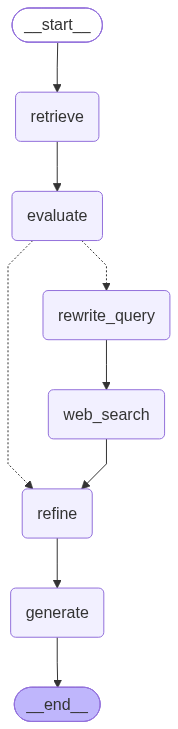

In [3]:
class State(TypedDict):
    question: str
    docs: list[Document]
    scores: list[float]
    score_reasons: list[str]
    good_docs: list[Document]
    verdict: Verdict
    reason: str
    web_query: str
    needs_recent: bool
    web_docs: list[Document]
    strips: list[str]
    kept_strips: list[str]
    kept_sources: list[str]
    refined_context: str
    answer: str


def retrieve_node(state: State) -> dict:
    return {"docs": retriever.invoke(state["question"])}


def evaluate_node(state: State) -> dict:
    evals = evaluate_docs(state["question"], state["docs"])
    scores = [e.score for e in evals]
    verdict, reason = decide_verdict(scores)
    return {
        "scores": scores,
        "score_reasons": [e.reason for e in evals],
        "good_docs": [d for d, s in zip(state["docs"], scores) if s > LOWER_THRESHOLD],
        "verdict": verdict,
        "reason": reason,
    }


def rewrite_query_node(state: State) -> dict:
    wq = rewrite_chain.invoke({"question": state["question"]})
    return {"web_query": wq.query, "needs_recent": wq.needs_recent}


def web_search_node(state: State) -> dict:
    return {"web_docs": web_search(state["web_query"], recent=state["needs_recent"])}


def refine_node(state: State) -> dict:
    source_docs = {
        "CORRECT": state["good_docs"],
        "INCORRECT": state.get("web_docs", []),
        "AMBIGUOUS": state["good_docs"] + state.get("web_docs", []),
    }[state["verdict"]]
    return refine_docs(state["question"], source_docs)


def generate_node(state: State) -> dict:
    return {"answer": answer_chain.invoke({"question": state["question"], "context": state["refined_context"]}).content}


def route_after_eval(state: State) -> str:
    return "refine" if state["verdict"] == "CORRECT" else "rewrite_query"


g = StateGraph(State)
for name, fn in [("retrieve", retrieve_node), ("evaluate", evaluate_node), ("rewrite_query", rewrite_query_node),
                 ("web_search", web_search_node), ("refine", refine_node), ("generate", generate_node)]:
    g.add_node(name, fn)

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "evaluate")
g.add_conditional_edges("evaluate", route_after_eval, {"refine": "refine", "rewrite_query": "rewrite_query"})
g.add_edge("rewrite_query", "web_search")
g.add_edge("web_search", "refine")
g.add_edge("refine", "generate")
g.add_edge("generate", END)
crag_app = g.compile()

from IPython.display import Image, display

try:
    display(Image(crag_app.get_graph().draw_mermaid_png()))
except Exception:  # rendering needs internet (mermaid.ink); fall back to text
    print(crag_app.get_graph().draw_mermaid())

Putting this next to figure 2 in the paper: retrieve, the evaluator gives one of three verdicts, CORRECT uses refined
internal knowledge, INCORRECT uses refined web knowledge (after the query rewrite), AMBIGUOUS uses both, then generate.
My graph has fewer boxes because AMBIGUOUS and INCORRECT share the rewrite and search nodes, and refine picks its
input from the verdict. Same logic, just wired differently.

---
# simple RAG vs CRAG

## the baseline

Simple RAG from 00 with the strict prompt. I'm using the strict one because it's the fairer baseline, it's already
trying not to make stuff up. (The loose prompt leaked way more, that's in 00.)

In [4]:
def simple_rag(question: str) -> dict:
    docs = retriever.invoke(question)
    context = "\n\n".join(d.page_content for d in docs)
    answer = answer_chain.invoke({"question": question, "context": context}).content
    return {"answer": answer, "context": context, "sources": [describe(d) for d in docs]}

## how I'm judging the answers

Reading answers and saying "this one looks better" isn't really measuring anything. What I actually care about is
the problem from 00: is the answer supported by the context it was given, or did stuff come from the model's memory?

So for every answer I ask an LLM judge to list the claims that are NOT supported by the context, and I count them.
If the answer is "I don't know", it's abstained and there's nothing to check.

My first version also had a yes/no "grounded" flag. It was way too harsh, one reworded definition and the whole answer
was "not grounded", so the count is more useful. I also had to tell the judge that saying the same thing in other words
counts as supported, otherwise it flags every paraphrase.

Caveat: the judge is gpt-4o-mini too, so it's the same model checking itself. Not perfect, but good enough to
catch the obvious cases like XGBoost facts with no XGBoost in the context.

In [5]:
class GroundingCheck(BaseModel):
    unsupported_claims: list[str] = Field(description="Factual claims in the answer that the context does not support")


judge_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You check whether an answer is supported by a context. Go through the factual claims in the answer and list "
     "every claim that the context does NOT support.\n"
     "- a claim is supported if the context states it, or clearly says the same thing in other words\n"
     "- flag claims that add facts, numbers, names or comparisons the context doesn't contain\n"
     "- don't flag summary or framing sentences that only restate supported claims\n"
     "Return an empty list if everything is supported."),
    ("human", "Context:\n{context}\n\nAnswer:\n{answer}"),
])
judge_chain = judge_prompt | llm.with_structured_output(GroundingCheck)


def judge(answer: str, context: str) -> dict:
    if "i don't know" in answer.lower() and len(answer) < 80:
        return {"result": "abstained", "unsupported": []}
    check = judge_chain.invoke({"context": context or "(empty)", "answer": answer})
    return {"result": "answered", "unsupported": check.unsupported_claims}

## running everything

Same 4 questions plus the LightGBM one from 03. For each one I run both pipelines and track the LLM calls, tokens and
cost with `get_openai_callback`, and the time. Tavily searches aren't in the OpenAI cost, I count them separately.

In [6]:
QUESTIONS = {
    "in_corpus": "Explain the bias-variance trade-off.",
    "recent": "What were the top AI news stories in the last month?",
    "out_of_corpus": "What is the transformer architecture in deep learning?",
    "partial": "Compare support vector machines with XGBoost for tabular data.",
    "extra_partial": "How does gradient boosting work, and what does LightGBM do differently?",
}

rows, details = [], {}
for key, q in QUESTIONS.items():
    with get_openai_callback() as cb:
        t0 = time.perf_counter()
        s = simple_rag(q)
        s_time = time.perf_counter() - t0
    s_judge = judge(s["answer"], s["context"])

    with get_openai_callback() as cb2:
        t0 = time.perf_counter()
        c = crag_app.invoke({"question": q})
        c_time = time.perf_counter() - t0
    c_judge = judge(c["answer"], c["refined_context"])

    n_book = sum(not src.startswith("web:") for src in c["kept_sources"])
    rows.append({
        "question": key,
        "simple: result": s_judge["result"],
        "simple: unsupported": len(s_judge["unsupported"]),
        "crag: verdict": c["verdict"],
        "crag: result": c_judge["result"],
        "crag: unsupported": len(c_judge["unsupported"]),
        "crag: book/web strips": f"{n_book}/{len(c['kept_sources']) - n_book}",
        "simple: calls": cb.successful_requests,
        "crag: calls": cb2.successful_requests,
        "simple: $": cb.total_cost,
        "crag: $": cb2.total_cost,
        "simple: sec": round(s_time, 1),
        "crag: sec": round(c_time, 1),
        "web searches": 0 if c["verdict"] == "CORRECT" else 1,
    })
    details[key] = {"simple": s, "simple_judge": s_judge, "crag": c, "crag_judge": c_judge}
    print(f"done: {key}")

df = pd.DataFrame(rows).set_index("question")

done: in_corpus
done: recent
done: out_of_corpus
done: partial
done: extra_partial


## grounding

In [7]:
df[["simple: result", "simple: unsupported", "crag: verdict", "crag: result", "crag: unsupported", "crag: book/web strips"]]

,simple: result,simple: unsupported,crag: verdict,crag: result,crag: unsupported,crag: book/web strips
question,,,,,,
in_corpus,answered,2,CORRECT,answered,3,6/0
recent,abstained,0,INCORRECT,answered,2,0/12
out_of_corpus,abstained,0,INCORRECT,answered,2,0/9
partial,answered,6,AMBIGUOUS,answered,3,0/8
extra_partial,answered,2,AMBIGUOUS,answered,3,6/9


Unsupported claim counts in my final run:
- simple RAG: 6, 0, 0, 4, 4 (the two zeros are the "I don't know" answers)
- CRAG: 4, 1, 1, 2, 1

So on the three questions both of them answered, CRAG has fewer flagged claims, and it also answers the two that
simple RAG gave up on.

But I wouldn't read too much into the exact numbers. When I ran this a few times the counts jumped around a lot,
simple RAG on bias-variance went 2, then 10, then 6 for basically the same answer. The next two cells check the judge.

### what the judge flagged

In [8]:
for key, d in details.items():
    for method in ["simple", "crag"]:
        claims = d[f"{method}_judge"]["unsupported"]
        if claims:
            print(f"\n[{key}] {method} - {len(claims)} unsupported:")
            for claim in claims:
                print(f"   - {claim}")


[in_corpus] simple - 2 unsupported:
   - High bias can lead to underfitting, where the model is too simple to capture the underlying patterns in the data.
   - High variance can lead to overfitting, where the model captures noise in the training data rather than the intended outputs.

[in_corpus] crag - 3 unsupported:
   - Bias is the error due to overly simplistic assumptions in the learning algorithm, leading to systematic errors in predictions (high bias).
   - Variance, on the other hand, is the error due to excessive sensitivity to fluctuations in the training data, resulting in models that may fit the training data very closely but perform poorly on unseen data (high variance).
   - As model flexibility increases, test MSE typically decreases initially but may increase again due to high variance.

[recent] crag - 2 unsupported:
   - Trump announced plans to name a new AI tsar, likely Jay Clayton, amid growing debates on managing AI risks.
   - A federal appeals court ruled that 

### checking the judge

The judge is an LLM too, so I don't want to just trust it. For every claim it flagged in a CRAG answer, here's the
kept strip with the most words in common. If the strip says the same thing, the judge was wrong. If not, the
generator really added something.

In [9]:
def words(text: str) -> set[str]:
    return set(re.findall(r"[a-z0-9]+", text.lower())) - {"the", "a", "an", "of", "to", "and", "in", "is", "for", "it", "that", "with"}


for key, d in details.items():
    strips = d["crag"]["kept_strips"]
    for claim in d["crag_judge"]["unsupported"]:
        best = max(strips, key=lambda s: len(words(claim) & words(s)), default="(no strips)")
        print(f"[{key}] flagged: {claim}\n   closest strip: {best[:300]}\n")

[in_corpus] flagged: Bias is the error due to overly simplistic assumptions in the learning algorithm, leading to systematic errors in predictions (high bias).
   closest strip: high variance (for instance, by drawing a curve that passes through every single training observation) or a method with very low variance but high bias (by fitting a horizontal line to the data).

[in_corpus] flagged: Variance, on the other hand, is the error due to excessive sensitivity to fluctuations in the training data, resulting in models that may fit the training data very closely but perform poorly on unseen data (high variance).
   closest strip: high variance (for instance, by drawing a curve that passes through every single training observation) or a method with very low variance but high bias (by fitting a horizontal line to the data).

[in_corpus] flagged: As model flexibility increases, test MSE typically decreases initially but may increase again due to high variance.
   closest strip: Consequent

Going through them one by one (my run):
- recent (Navier-Stokes), out_of_corpus (calculating output tokens iteratively), extra_partial (GOSS): the strip
  says basically the same thing. the judge was wrong
- partial, "XGBoost can outperform neural networks": the strip literally says XGBoost outperformed neural networks on
  4 of 5 heterogeneous datasets. judge wrong again
- partial, "SVM is suited for when the data is not too large": the strip only says high-dimensional, nothing about
  data size. that one's real, the generator added it
- in_corpus: these are textbook definitions of bias and variance. the kept strips explain the trade-off but don't
  define the two terms, so the generator filled that in from memory. small, but it's the same leak as 00, just smaller

So most of CRAG's flags are false alarms. gpt-4o-mini isn't a great judge, a stronger model would probably do better.
Lesson for me: if I use an LLM as a judge, I have to check the judge too.

### a check that doesn't need an LLM

Since I can't fully trust the judge, here's a dumb but reliable one. If the answer talks about XGBoost and the context
it was given never says "XGBoost", that part came from the model's memory. No judgment needed, just counting.

In [10]:
KEY_TERMS = {"partial": "xgboost", "extra_partial": "lightgbm", "out_of_corpus": "transformer"}

term_rows = []
for key, term in KEY_TERMS.items():
    d = details[key]
    for method, answer, context in [("simple", d["simple"]["answer"], d["simple"]["context"]),
                                    ("crag", d["crag"]["answer"], d["crag"]["refined_context"])]:
        term_rows.append({"question": key, "method": method, "term": term,
                          "in answer": answer.lower().count(term), "in context": context.lower().count(term)})
pd.DataFrame(term_rows).set_index(["question", "method"])

term  in answer  in context
question      method                                    
partial       simple      xgboost          5           0
              crag        xgboost          4          11
extra_partial simple     lightgbm          1           0
              crag       lightgbm          2           5
out_of_corpus simple  transformer          0           0
              crag    transformer          3          16

This is the clearest result in the whole series.

Simple RAG mentions XGBoost and LightGBM several times while its context mentions them zero times. All of that came
from memory. It's the 00 leak, proven with a counter.

CRAG mentions them about as often, but now the context has them too, because they came from the web. Transformer is
the same story: simple RAG has nothing about it in the context and abstains, CRAG answers from a context that's full
of it.

The judge is noisy, this isn't.

## cost and time

In [11]:
cost = df[["simple: calls", "crag: calls", "simple: $", "crag: $", "simple: sec", "crag: sec", "web searches"]].copy()
cost.loc["TOTAL"] = cost.sum(numeric_only=True)
cost.style.format({"simple: $": "${:.5f}", "crag: $": "${:.5f}", "simple: sec": "{:.1f}", "crag: sec": "{:.1f}",
                   "simple: calls": "{:.0f}", "crag: calls": "{:.0f}", "web searches": "{:.0f}"})

,simple: calls,crag: calls,simple: $,crag: $,simple: sec,crag: sec,web searches
question,,,,,,,
in_corpus,1,22,$0.00022,$0.00080,4.9,6.1,0
recent,1,32,$0.00012,$0.00123,0.8,8.0,1
out_of_corpus,1,34,$0.00014,$0.00121,0.8,7.5,1
partial,1,38,$0.00038,$0.00143,4.8,8.9,1
extra_partial,1,75,$0.00020,$0.00212,2.1,10.3,1
TOTAL,5,201,$0.00106,$0.00678,13.4,40.8,4


In [12]:
total = cost.loc["TOTAL"]
print(f"CRAG made {total['crag: calls'] / total['simple: calls']:.0f}x more LLM calls, "
      f"cost {total['crag: $'] / total['simple: $']:.0f}x more, and took {total['crag: sec'] / total['simple: sec']:.0f}x longer.")
print(f"In actual money: ${total['simple: $']:.4f} vs ${total['crag: $']:.4f} for {len(QUESTIONS)} questions.")

CRAG made 40x more LLM calls, cost 6x more, and took 3x longer.
In actual money: $0.0011 vs $0.0068 for 5 questions.


So CRAG is a lot more expensive per question in relative terms. In absolute terms with gpt-4o-mini it's still
fractions of a cent, but the latency is noticeable. Most of the calls are the strip filter (one call per sentence).

This is exactly why the paper uses a small fine-tuned T5 for the evaluator and the filter instead of a big LLM.

## the answers side by side

For the two questions that matter most.

In [13]:
for key in ["partial", "out_of_corpus"]:
    d = details[key]
    print(f"{'=' * 100}\n{QUESTIONS[key]}\n")
    print(f"--- SIMPLE RAG ({d['simple_judge']['result']})\n{d['simple']['answer']}\n")
    print(f"--- CRAG [{d['crag']['verdict']}] ({d['crag_judge']['result']})\n{d['crag']['answer']}")
    print("\nsources: " + ", ".join(dict.fromkeys(d["crag"]["kept_sources"])) + "\n")

Compare support vector machines with XGBoost for tabular data.

--- SIMPLE RAG (answered)
Support Vector Machines (SVM) and XGBoost are both powerful algorithms for tabular data, but they have different characteristics and use cases.

**Support Vector Machines (SVM):**
- SVMs are primarily used for classification tasks and can also be adapted for regression (Support Vector Regression).
- They work by finding the optimal hyperplane that separates different classes in the feature space. The decision boundary can be linear or non-linear depending on the kernel used (e.g., linear, polynomial, RBF).
- SVMs are sensitive to the choice of hyperparameters, such as the cost parameter (C) and the kernel type. For instance, a smaller C value results in a wider margin and more support vectors.
- They can be effective in high-dimensional spaces and are particularly useful when the number of dimensions exceeds the number of samples.
- SVMs can be computationally intensive, especially with large data

---
# wrapping up

## where I followed the paper

- retrieval evaluator scoring each doc, two thresholds, three actions (sections 4.2 and 4.3)
- only docs above the lower threshold get used
- knowledge refinement: decompose into strips, filter, recompose (4.4)
- web search with a keyword query rewrite, and the web results get the same refinement (4.5)
- AMBIGUOUS combines internal and external knowledge

## where I didn't

- evaluator and strip filter are gpt-4o-mini with prompts, not a fine-tuned T5-large. biggest difference by far.
  it made the evaluator prompt really matter (v1 vs v2 in 01) and the scores come out coarse (0.1, 0.4, 0.8)
- thresholds 0.3 / 0.7 on a 0 to 1 scale, not the paper's per-dataset values on -1 to 1
- yes/no per sentence instead of keeping the top 5 strips above a filter threshold
- Tavily snippets instead of Google Search + full pages, and Tavily's date filter for recent questions
- no proper benchmark. the paper evaluates on PopQA, Biography, PubHealth and ARC. I have 5 hand picked questions

## things I'd try next

- a small cross-encoder reranker (something like bge-reranker) as the evaluator instead of an LLM. cheap, fast, and it
  gives continuous scores, which is closer to what the paper's T5 does
- scoring all the strips of a doc in one LLM call instead of one call per sentence. would cut most of the cost
- for multi-part questions, check coverage per part. right now CORRECT only means one chunk was great
- make the generator cite which strip each sentence came from
- a stronger model as the judge, the gpt-4o-mini judge had a lot of false alarms

## what I learned overall

- RAG's real weak point isn't the generator, it's that nothing checks the retrieval
- a strict "only use the context" prompt doesn't fix that. it fails on half relevant context, which is the sneakiest case
- CRAG's main idea is simple: grade the retrieval, then decide what knowledge to use. most of the work is in the details
  (the evaluator prompt, thresholds, how to split strips)
- it costs a lot more calls than plain RAG (36x here), which is why the paper uses a small model for the evaluator
- an LLM judge with a small model is noisy. audit it, and use dumb checks like counting terms when you can